# Series Temporals

Un dels problemes clàsics del machine learning és predir el futur en base a les tendències del passat. 

Els algorismes de series temporals no són distints als de regressió o classificació clàsics o al deep learning que ja hem vist. El que canvia és la manera de preparar els datasets i entrenar. Molts algorismes de Machine Learning (com Random Forest, XGBoost) o de Deep Learning (com xarxes neuronals tridimensionals o lineals) no entenen el concepte "temporal" per si sols. Per ensenyar-los a predir el futur, transformem la sèrie temporal en un dataset de regressió tradicional mitjançant la tècnica de finestres lliscants (sliding windows) o retards (lags).

Anem a distingir entre resoldre una serie temporal amb **Models No autoregressius** o **Contemporanis** que utilitzen variables `exògenes` i models **Autoregressius** que es basen en retards o `lags`. 

Una serie temporal **Autoregressiva** prediu un valor futur en base a `N` observacions del passat fins al moment. Per tant, les variables són la mateixa variable observada `N` vegades fins al moment.  

L'ordre temporal importa (No-iid): En regressió clàssica, les files del dataset són independents i idènticament distribuïdes (iid), per la qual cosa pots fer un train_test_split barrejant les dades aleatòriament. En sèries temporals mai pots barrejar el futur amb el passat per entrenar, ja que cauries en data leakage (fuga de dades). Cal dividir les dades de manera estrictament cronològica.

**Variables exògenes** (Sèries multivariades): Tot i que sovint prediguem una variable en funció del seu propi passat, moltes vegades afegim variables externes o exògenes (per exemple, predir la demanda d'energia basant-nos no només en el consum passat, sinó també en la temperatura prevista o els dies festius).

Encara que l'enfocament de regressió amb lags funciona molt bé, existeixen famílies de models estadístics tradicionals (com ARIMA o Exponential Smoothing) i models específics de Deep Learning (com LSTMs, GRUs o Transformers de sèries temporals) dissenyats nativament per capturar dependències temporals sense necessitat de calcular manualment tots els lags.

## Solució NO Autorregressiva amb XGBoost

Models basats en arbres com XGBoost (o LightGBM) s'utilitzen en sèries temporals i, moltes vegades, poden competir de tu a tu (o fins i tot superar) a les xarxes LSTM, amb l'avantatge enorme que s'entrenen en una fracció del temps.

XGBoost té suport natiu per a regressió multi-output (Multi-target regression). Això significa que pots passar-li una matriu d'objectius y de forma (Batch, 24), i XGBoost s'encarregarà d'entrenar els arbres de decisió per predir les 24 sortides simultàniament en una sola passada.

> L'exemple a continuació és una reinterpretació de: https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import datetime
import matplotlib.ticker as ticker


In [2]:
from sklearn.datasets import fetch_openml

bike_sharing = fetch_openml("Bike_Sharing_Demand", version=2, as_frame=True)
df = bike_sharing.frame

In [3]:
print(df.info())
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   season      17379 non-null  category
 1   year        17379 non-null  int64   
 2   month       17379 non-null  int64   
 3   hour        17379 non-null  int64   
 4   holiday     17379 non-null  category
 5   weekday     17379 non-null  int64   
 6   workingday  17379 non-null  category
 7   weather     17379 non-null  category
 8   temp        17379 non-null  float64 
 9   feel_temp   17379 non-null  float64 
 10  humidity    17379 non-null  float64 
 11  windspeed   17379 non-null  float64 
 12  count       17379 non-null  int64   
dtypes: category(4), float64(4), int64(5)
memory usage: 1.3 MB
None


,season,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed,count
0,spring,0,1,0,False,6,False,clear,9.84,14.395,0.81,0.0,16
1,spring,0,1,1,False,6,False,clear,9.02,13.635,0.80,0.0,40
2,spring,0,1,2,False,6,False,clear,9.02,13.635,0.80,0.0,32
3,spring,0,1,3,False,6,False,clear,9.84,14.395,0.75,0.0,13
4,spring,0,1,4,False,6,False,clear,9.84,14.395,0.75,0.0,1


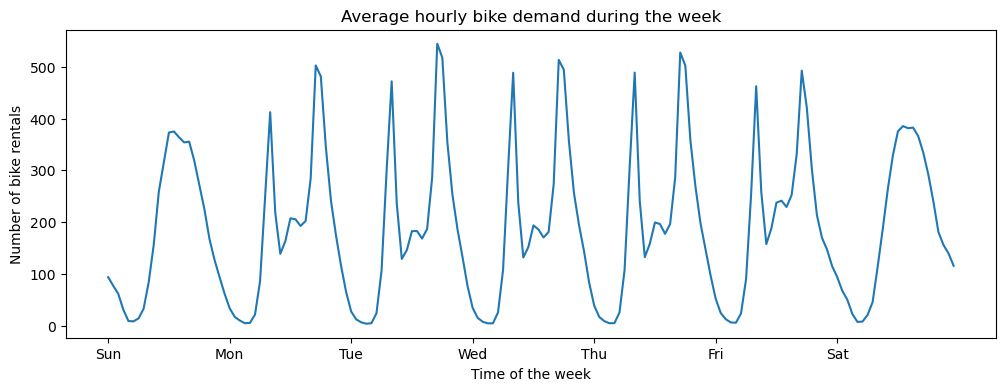

In [4]:

fig, ax = plt.subplots(figsize=(12, 4))
average_week_demand = df.groupby(["weekday", "hour"])["count"].mean()
average_week_demand.plot(ax=ax)
_ = ax.set(
    title="Average hourly bike demand during the week",
    xticks=[i * 24 for i in range(7)],
    xticklabels=["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"],
    xlabel="Time of the week",
    ylabel="Number of bike rentals",
)


El que tenim és un dataset de demanda de bicicletes per a alquiler amb varies columnes i una variable `target` que és `count`. Es poden distingir clarament el comportament diferent el cap de setmana respecte a la resta de dies. 

Veiem que el número màxim de bicicletes alquilades en una hora són 977, però la gràfica està mostrant la mitjana de cada hora de totes les observacions. 

In [22]:
df["count"].max()

np.int64(977)

Conforme al manual oficial, anem a reescalar la variable target per mostrar el percentatge respecte al màxim. És una normalització que pot servir per explicar millor l'error del model:

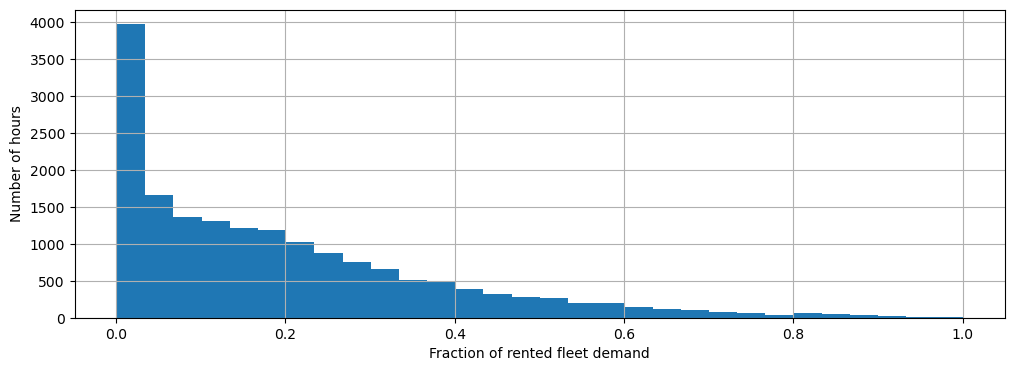

In [5]:
y = df["count"] / df["count"].max()
fig, ax = plt.subplots(figsize=(12, 4))
y.hist(bins=30, ax=ax)
_ = ax.set(
    xlabel="Fraction of rented fleet demand",
    ylabel="Number of hours",
)


In [6]:
X = df.drop("count", axis="columns")
X

,season,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed
0,spring,0,1,0,False,6,False,clear,9.84,14.395,0.81,0.0000
1,spring,0,1,1,False,6,False,clear,9.02,13.635,0.80,0.0000
2,spring,0,1,2,False,6,False,clear,9.02,13.635,0.80,0.0000
3,spring,0,1,3,False,6,False,clear,9.84,14.395,0.75,0.0000
4,spring,0,1,4,False,6,False,clear,9.84,14.395,0.75,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...
17374,spring,1,12,19,False,1,True,misty,10.66,12.880,0.60,11.0014
17375,spring,1,12,20,False,1,True,misty,10.66,12.880,0.60,11.0014
17376,spring,1,12,21,False,1,True,clear,10.66,12.880,0.60,11.0014
17377,spring,1,12,22,False,1,True,clear,10.66,13.635,0.56,8.9981


Les dades del temps estan perfectes, ja que tenim l'any, mes, hora, dia de la setmana per separat. Si no deuriem separar-les per a que foren numériques. 

No obstant, la variable `weather` té un problema: 

In [25]:
X["weather"].value_counts()

weather
clear         11413
misty          4544
rain           1419
heavy_rain        3
Name: count, dtype: int64

Està molt desequilibrada i amb sols 3 mostres no va a funcionar `cross-validation`. La juntem amb `rain`

In [7]:
X["weather"] = (
    X["weather"]
    .astype(object)
    .replace(to_replace="heavy_rain", value="rain")
    .astype("category")
)
X["weather"].value_counts()

weather
clear    11413
misty     4544
rain      1422
Name: count, dtype: int64

### Cross-Validation per a series temporals

El dataset és ordenat i això canvia totalment la manera de separar les dades de validació. Ja no podem seleccionar files aleatories ni desordenar-les abans de separar. 

Utilitzarem `TimeSeriesSplit` per separar respectant l'ordre de les dades. Amés, deixarem 48 hores entre les dades de train i les de test per evitar que el model veja el "futur immediat" i limitarem les dades de train a 10000 per questions d'estabilitat. És a dir que el model no pateix sotracs inesperats ni per tenir volums de dades fluctuants entre plecs, ni per arrossegar informació antiquada que ja no descriu el comportament actual de la demanda. També limitem les dades de test a 1000, que és poc menys que un mes i representa prou be la qualitat del model. 

> ***Barrejar les dades?*** Per a un `HistGradientBoostingRegressor` que anem a fer no és necessari barrejar les dades d'entrenament. Si anarem a fer qualsevol model amb gradient descendent com `SGDRegressor` és precís barrejar (sempre després de separar) per a evitar efecte inèrcia a l'entrenament (`shuffle=True`). Com veurem a les xarxes neuronals per a series temporals està prohibit barrejar, ja que accepten les dades una a una seqüencialment. 

In [8]:
from sklearn.model_selection import TimeSeriesSplit

ts_cv = TimeSeriesSplit(
    n_splits=5,
    gap=48,
    max_train_size=10000,
    test_size=1000,
)

In [9]:
all_splits = list(ts_cv.split(X, y))
train_0, test_0 = all_splits[0]

print(test_0[:10])
print(train_0[:10])

[12379 12380 12381 12382 12383 12384 12385 12386 12387 12388]
[2331 2332 2333 2334 2335 2336 2337 2338 2339 2340]


In [10]:
train_0.shape, test_0.shape

((10000,), (1000,))

In [11]:
X.iloc[test_0]

,season,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed
12379,summer,1,6,0,False,2,True,clear,22.14,25.760,0.68,27.9993
12380,summer,1,6,1,False,2,True,misty,21.32,25.000,0.77,22.0028
12381,summer,1,6,2,False,2,True,rain,21.32,25.000,0.72,19.9995
12382,summer,1,6,3,False,2,True,rain,20.50,24.240,0.82,12.9980
12383,summer,1,6,4,False,2,True,rain,20.50,24.240,0.82,12.9980
...,...,...,...,...,...,...,...,...,...,...,...,...
13374,fall,1,7,11,False,1,True,clear,34.44,40.150,0.53,15.0013
13375,fall,1,7,12,False,1,True,clear,34.44,39.395,0.49,8.9981
13376,fall,1,7,13,False,1,True,clear,34.44,39.395,0.49,19.0012
13377,fall,1,7,14,False,1,True,clear,36.08,40.910,0.42,7.0015


### HistGradientBoostingRegressor 

Recordem que HistGradientBoostingRegressor és la versió de `Scikit-learn` de l'algorisme `XGBoost`. Amés, suporta variables categòriques de forma nativa posant `categorical_features="from_dtype"`

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline

gbrt = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=42)
categorical_columns = X.columns[X.dtypes == "category"]
print("Categorical features:", categorical_columns.tolist())

Categorical features: ['season', 'holiday', 'workingday', 'weather']


In [ ]:
cv_results = cross_validate(
        gbrt,
        X,
        y,
        cv=ts_cv, # Utilitzem les particios temporals
        scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error"],
        return_estimator=True,
    )


{'fit_time': array([0.59582663, 0.43752766, 0.44226861, 0.43521309, 0.44554448]), 'score_time': array([0.01708651, 0.01632452, 0.01568604, 0.01646423, 0.01565337]), 'estimator': [HistGradientBoostingRegressor(random_state=42), HistGradientBoostingRegressor(random_state=42), HistGradientBoostingRegressor(random_state=42), HistGradientBoostingRegressor(random_state=42), HistGradientBoostingRegressor(random_state=42)], 'test_neg_mean_absolute_error': array([-0.04115399, -0.04505202, -0.0457406 , -0.04084856, -0.04836914]), 'test_neg_root_mean_squared_error': array([-0.06094834, -0.06838686, -0.07008036, -0.0630599 , -0.07538134])}


In [16]:

print(-cv_results["test_neg_mean_absolute_error"])

[0.04115399 0.04505202 0.0457406  0.04084856 0.04836914]


El resultat és aproximadament un 4% d'error respecte a la màxima demanda. És un resultat molt bó inclús sense ajustar massa hiperparàmetres. 

In [22]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# 1. Definim el TimeSeriesSplit
ts_cv_final = TimeSeriesSplit(
    n_splits=2, gap=48, max_train_size=10000, test_size=1000
)

# 2. Convertim el generador a llista i agafem l'últim split (-1)
train_index, test_index = list(ts_cv_final.split(X))[-1]

# 3. Separem les dades
X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]

# 4. Entrenem i avaluem
gbrt.fit(X_train, y_train)
y_pred = gbrt.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE al Test Final: {mae:.4f}")
print(f"RMSE al Test Final: {rmse:.4f}")
print(f"R2 al Test Final: {r2:.4f}")



MAE al Test Final: 0.0484
RMSE al Test Final: 0.0754
R2 al Test Final: 0.8002


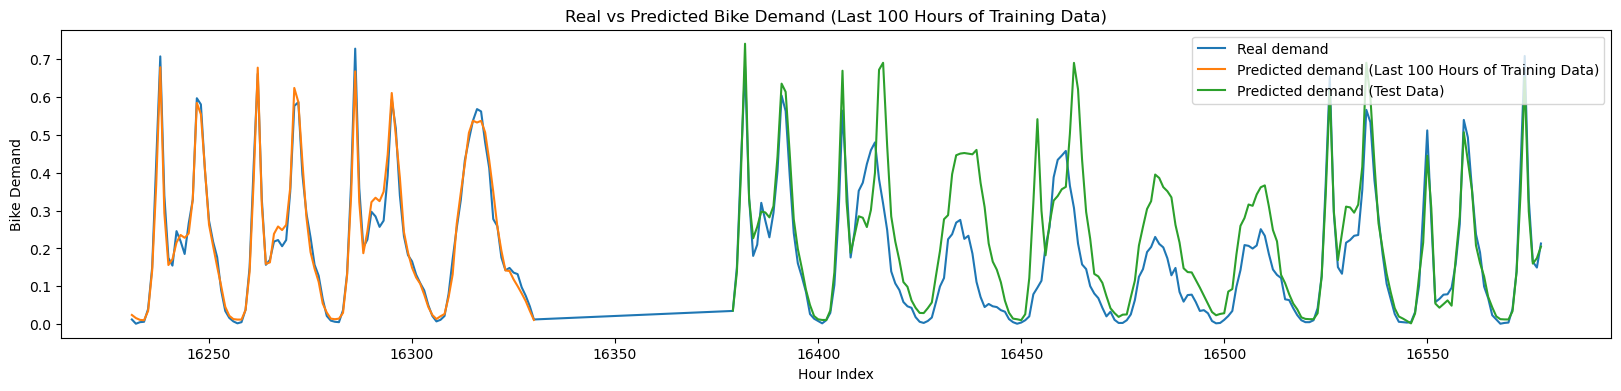

In [36]:
X_train_last_100 = X_train.tail(100)
y_train_last_100 = y_train.tail(100)

X_plot = pd.concat([X_train_last_100, X_test.head(200)])
y_plot = pd.concat([y_train_last_100, y_test.head(200)])

plt.figure(figsize=(20, 4))
plt.plot(X_plot.index, y_plot, label="Real demand")
plt.plot(X_train_last_100.index, gbrt.predict(X_train_last_100), label="Predicted demand (Last 100 Hours of Training Data)")
plt.plot(X_test.head(200).index, gbrt.predict(X_test.head(200)), label="Predicted demand (Test Data)")
plt.title("Real vs Predicted Bike Demand (Last 100 Hours of Training Data)")
plt.xlabel("Hour Index")
plt.ylabel("Bike Demand")
plt.legend()

## Solució Autoregressiva amb XGBoost

La solució anterior en realitat no té molt de serie temporal, ja que no s'observen valors en les variables del passat per a fer una predicció. Això és gràcies a que el dataset tenia moltes variables `exògenes`. Però si sols depenem del valor observat en un històric passat ja no tenim aquestes variables en les que comptar. 

Es pot fer perfectament un `model híbrid` amb variables exògenes i variables autorregressives com la demanda de les últimes hores. 

Com que comptem amb variables molt valuoses que ens han donat tant bons resultats, anem a afegir el component de autorregressiò i observar quins resultats dona.

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import datetime
import matplotlib.ticker as ticker
from sklearn.datasets import fetch_openml

bike_sharing = fetch_openml("Bike_Sharing_Demand", version=2, as_frame=True)
df = bike_sharing.frame

y = df["count"] / df["count"].max()
X = df.drop("count", axis="columns")
X["weather"] = (
    X["weather"]
    .astype(object)
    .replace(to_replace="heavy_rain", value="rain")
    .astype("category")
)

X.head()

,season,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed
0,spring,0,1,0,False,6,False,clear,9.84,14.395,0.81,0.0
1,spring,0,1,1,False,6,False,clear,9.02,13.635,0.80,0.0
2,spring,0,1,2,False,6,False,clear,9.02,13.635,0.80,0.0
3,spring,0,1,3,False,6,False,clear,9.84,14.395,0.75,0.0
4,spring,0,1,4,False,6,False,clear,9.84,14.395,0.75,0.0


In [54]:
lags_dict = {}
for h in range(6, 49, 6):  # Genera: 6, 12, 18, 24, 30, 36, 42, 48
  lags_dict[f"demanda_lag_{h}"] = y.shift(h)
lags_df = pd.DataFrame(lags_dict, index=y.index)
lags_df.tail(10)

,demanda_lag_6,demanda_lag_12,demanda_lag_18,demanda_lag_24,demanda_lag_30,demanda_lag_36,demanda_lag_42,demanda_lag_48
17369,0.200614,0.011259,0.073695,0.163767,0.033777,0.019447,0.067554,0.100307
17370,0.160696,0.001024,0.048106,0.141249,0.075742,0.015353,0.061412,0.132037
17371,0.122825,0.003071,0.036847,0.136131,0.124872,0.007165,0.055271,0.150461
17372,0.160696,0.009212,0.050154,0.125896,0.139202,0.002047,0.032753,0.120778
17373,0.229273,0.040942,0.034800,0.127943,0.147390,0.008188,0.041965,0.112590
17374,0.207779,0.087001,0.019447,0.104401,0.172979,0.013306,0.028659,0.099284
17375,0.252815,0.200614,0.011259,0.073695,0.163767,0.033777,0.019447,0.067554
17376,0.322416,0.160696,0.001024,0.048106,0.141249,0.075742,0.015353,0.061412
17377,0.219038,0.122825,0.003071,0.036847,0.136131,0.124872,0.007165,0.055271
17378,0.167861,0.160696,0.009212,0.050154,0.125896,0.139202,0.002047,0.032753


In [58]:
X_concat = pd.concat([X, lags_df], axis=1)
X_net = X_net.dropna() # Eliminem les files amb valors nuls (NaN) que s'han generat a causa dels lags. Això és necessari perquè els models de machine learning no poden manejar valors nuls en les dades d'entrada.
y_net = y.loc[X_net.index]
X_net

,season,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed,demanda_lag_6,demanda_lag_12,demanda_lag_18,demanda_lag_24,demanda_lag_30,demanda_lag_36,demanda_lag_42,demanda_lag_48
48,spring,0,1,1,False,1,True,clear,8.20,8.335,0.44,27.9993,0.030706,0.076766,0.001024,0.017400,0.035824,0.085977,0.002047,0.016377
49,spring,0,1,4,False,1,True,clear,6.56,6.820,0.47,26.0027,0.022518,0.060389,0.008188,0.017400,0.037871,0.096213,0.003071,0.040942
50,spring,0,1,5,False,1,True,clear,6.56,6.820,0.47,19.0012,0.031730,0.075742,0.020471,0.009212,0.036847,0.108495,0.008188,0.032753
51,spring,0,1,6,False,1,True,clear,5.74,5.305,0.50,26.0027,0.009212,0.077789,0.054248,0.006141,0.034800,0.112590,0.014330,0.013306
52,spring,0,1,7,False,1,True,clear,5.74,6.820,0.50,12.9980,0.008188,0.066530,0.071648,0.003071,0.028659,0.095189,0.036847,0.001024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,spring,1,12,19,False,1,True,misty,10.66,12.880,0.60,11.0014,0.207779,0.087001,0.019447,0.104401,0.172979,0.013306,0.028659,0.099284
17375,spring,1,12,20,False,1,True,misty,10.66,12.880,0.60,11.0014,0.252815,0.200614,0.011259,0.073695,0.163767,0.033777,0.019447,0.067554
17376,spring,1,12,21,False,1,True,clear,10.66,12.880,0.60,11.0014,0.322416,0.160696,0.001024,0.048106,0.141249,0.075742,0.015353,0.061412
17377,spring,1,12,22,False,1,True,clear,10.66,13.635,0.56,8.9981,0.219038,0.122825,0.003071,0.036847,0.136131,0.124872,0.007165,0.055271


In [56]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline

ts_cv = TimeSeriesSplit(
    n_splits=5,
    gap=48,
    max_train_size=10000,
    test_size=1000,
)


In [57]:
gbrt = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=42)

cv_results = cross_validate(
        gbrt,
        X_net,
        y_net,
        cv=ts_cv, # Utilitzem les particios temporals
        scoring=["r2"],
        return_estimator=True,
    )
print(-cv_results["test_r2"])

[-0.91144047 -0.90608307 -0.91455091 -0.89166347 -0.8253773 ]


MAE al Test Final: 0.0483
RMSE al Test Final: 0.0705
R2 al Test Final: 0.8254


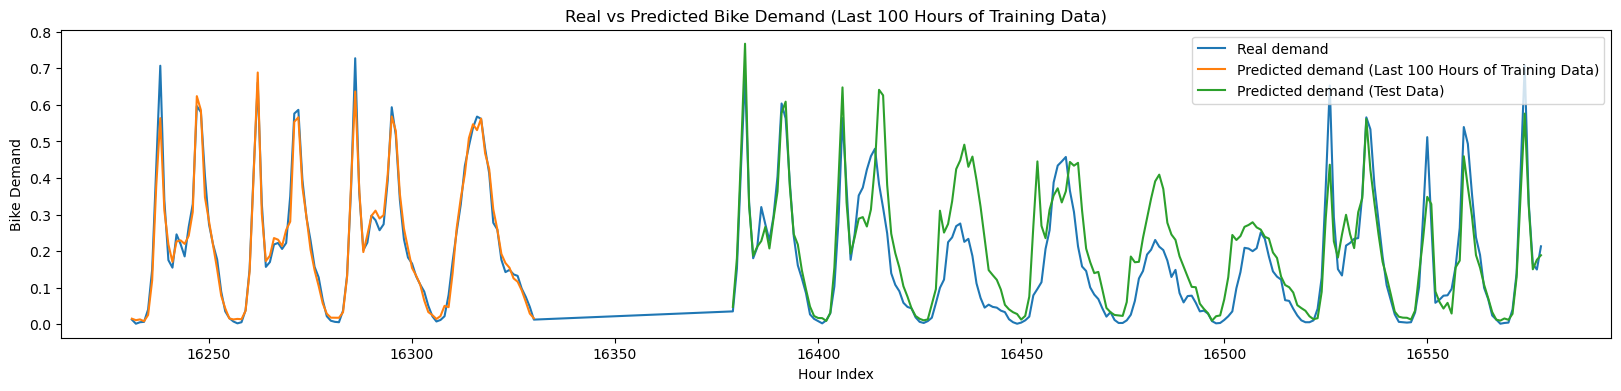

In [60]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

ts_cv_final = TimeSeriesSplit(
    n_splits=2, gap=48, max_train_size=10000, test_size=1000
)

# 2. Convertim el generador a llista i agafem l'últim split (-1)
train_index, test_index = list(ts_cv_final.split(X_net))[-1]

# 3. Separem les dades
X_train, X_test = X_net.iloc[train_index], X_net.iloc[test_index]
y_train, y_test = y_net.iloc[train_index], y_net.iloc[test_index]

# 4. Entrenem i avaluem
gbrt.fit(X_train, y_train)
y_pred = gbrt.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE al Test Final: {mae:.4f}")
print(f"RMSE al Test Final: {rmse:.4f}")
print(f"R2 al Test Final: {r2:.4f}")

X_train_last_100 = X_train.tail(100)
y_train_last_100 = y_train.tail(100)

X_plot = pd.concat([X_train_last_100, X_test.head(200)])
y_plot = pd.concat([y_train_last_100, y_test.head(200)])

plt.figure(figsize=(20, 4))
plt.plot(X_plot.index, y_plot, label="Real demand")
plt.plot(X_train_last_100.index, gbrt.predict(X_train_last_100), label="Predicted demand (Last 100 Hours of Training Data)")
plt.plot(X_test.head(200).index, gbrt.predict(X_test.head(200)), label="Predicted demand (Test Data)")
plt.title("Real vs Predicted Bike Demand (Last 100 Hours of Training Data)")
plt.xlabel("Hour Index")
plt.ylabel("Bike Demand")
plt.legend()


## Series temporals amb xarxes neuronals

In [2]:
import numpy as np

with open("datos_temperatura.csv", "r") as datafile:

    ts_list_train = []

    for line in datafile:
        row = np.array(
            [float(x) for x in line.strip().split(",") if x != ""],
            dtype=np.float32
        )

        ts_list_train.append(row)

In [3]:
print("Files in ts_list_train:", len(ts_list_train))
print("Length of the first time series:", len(ts_list_train[0]))

Files in ts_list_train: 12
Length of the first time series: 44436


### Estructura i Transformació de Dades per a Xarxes Neuronals en Sèries Temporals

En projectes de Machine Learning i Deep Learning aplicats a sèries temporals multi-entitat (com dades meteorològiques de múltiples ciutats), l'elecció de l'estructura de dades i la seva transformació a tensors de dimensions específiques és crítica per garantir l'eficiència computacional.

Per a un conjunt de dades compost per **12 ciutats** i un registre històric aproximat de **44.436 valors temporals** per cadascuna d'elles, l'organització òptima de les dades crues s'estructura generalment en una matriu o **format ample (*wide format*)**:

* **Files:** Entitats úniques (ciutats).
* **Columnes:** Eix temporal seqüencial.

Aquest enfocament evita la sobrecàrrega de memòria RAM que suposaria gestionar un format llarg (*long* o *tidy*) amb centenars de milers de files repetitives, facilitant el càlcul vectoritzat per a la normalització i la extracció de seqüències.

Per tal d'entrenar models de Deep Learning (com xarxes neuronals recurrents LSTM, GRU o arquitectures convolucionals 1D), les dades s'han de processar mitjançant la tècnica de **finestres lliscants (*sliding windows*)**. Aquest procés transforma la matriu bidimensional original en un tensor tridimensional.

En l'àmbit de l'anàlisi de dades, les sèries temporals multi-entitat es poden estructurar principalment en dos formats: el **format ample (*wide*)**, on cada fila representa una entitat única (com una ciutat) i les columnes actuen com a eix temporal, sent ideal per a comparacions visuals directes i càlculs matricials; i el **format llarg (*long* o *tidy*)**, on cada fila correspon a una observació individual i datada per a cada entitat, sent aquest últim l'estàndard recomanat per a pipelines de Machine Learning i llibreries analítiques gràcies a la seva flexibilitat per gestionar múltiples variables i operacions d'agrupació.

### Dibuixar la serie temporal


In [6]:
headers = ['San Francisco', 'Los Angeles', 'Las Vegas', 'Dallas', 'Houston',
           'Chicago', 'Detroit', 'Miami', 'Toronto', 'Philadelphia',
           'New York', 'Boston']

# Fecha inicial:  1 de octubre de 2012 a las 13:00 horas.
initial_moment = datetime.datetime(2012, 10, 1, 13, 0)

colors = plt.get_cmap('Set1', len(headers)) # treure tants colors com ciutats hi ha del cmap Set1

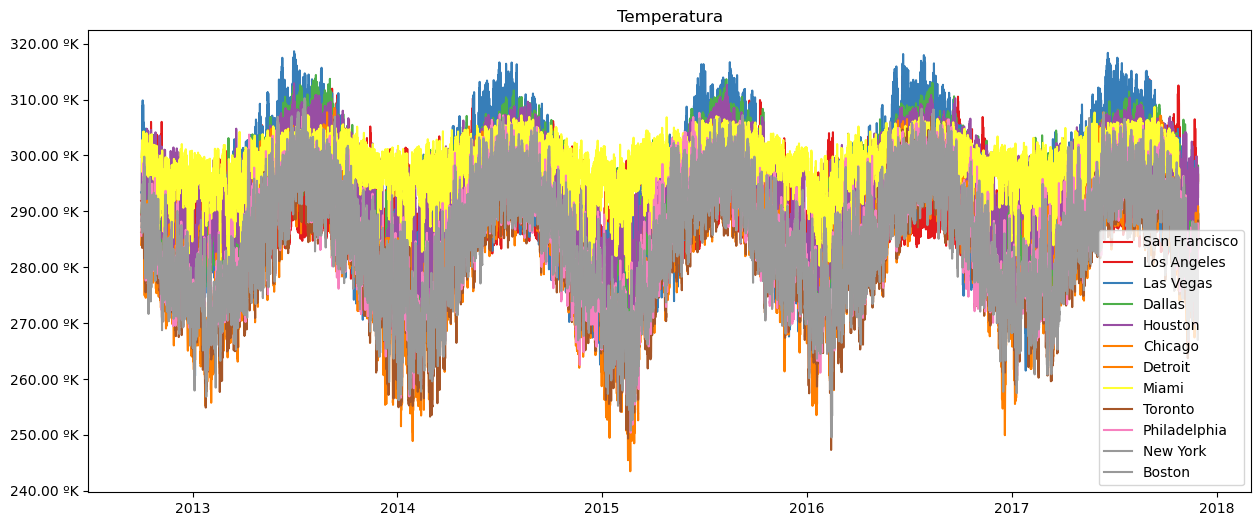

In [9]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15,6))
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%1.2f ºK'))

for i in range(len(headers)):
  # Generem una llista de dates a partir de la data inicial, afegint una hora per cada valor de la sèrie temporal
  x = [initial_moment + datetime.timedelta(hours=j, minutes=0) for j in range(ts_list_train[i].shape[0])]
  ax.plot(x, ts_list_train[i], label=headers[i], c=colors(i))
ax.legend()
ax.set_title("Temperatura")
plt.show()

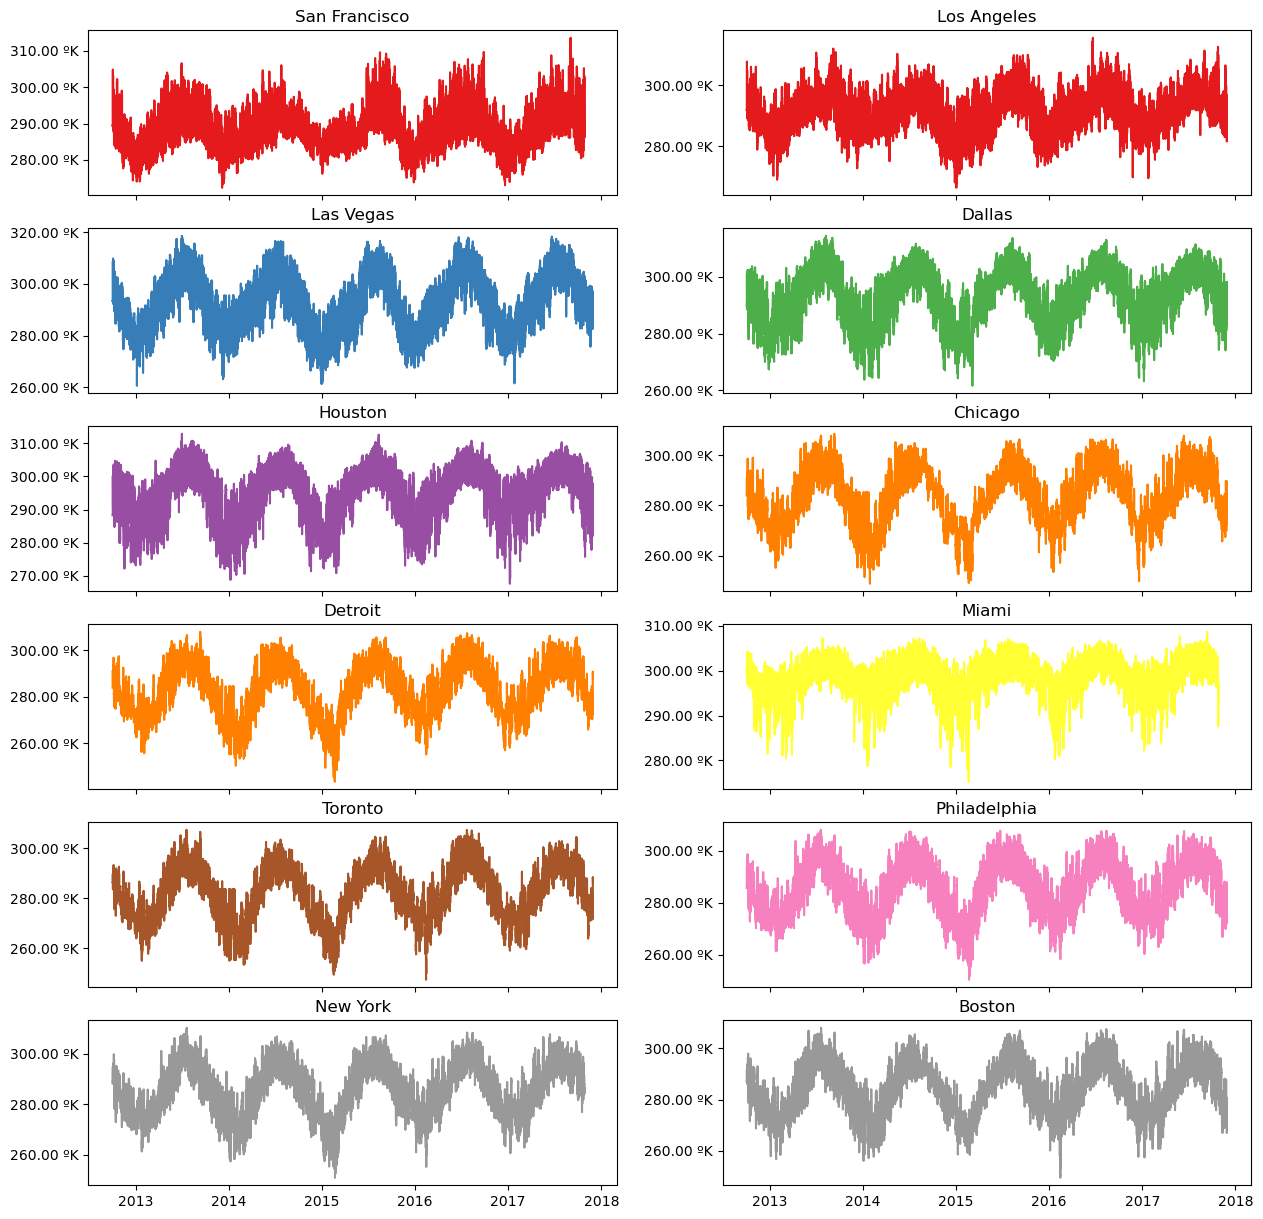

In [12]:


fig, ax = plt.subplots(nrows=np.ceil(len(headers)/2).astype(int), ncols=2, figsize=(15,15), sharex=True)

for i in range(len(headers)):

  x = [initial_moment + datetime.timedelta(hours=j, minutes=0)for j in range(ts_list_train[i].shape[0])]
  ax[i//2][i%2].yaxis.set_major_formatter(ticker.FormatStrFormatter('%1.2f ºK'))
  ax[i//2][i%2].set_title(headers[i])
  ax[i//2][i%2].plot(x, ts_list_train[i], label=headers[i], c=colors(i))

plt.show()

Com que hi ha ciutats amb temperatures més extremes cal normalitzar les dades. No utilitzem `StandardScaler` perquè l'estructura de les dades no està per columnes i perquè volem normalitzar fila a fila. Amés, normalitzem com fa MinMax perquè les xarxes neuronals poden exigir valors entre 0 i 1. Per fer-ho més ràpid transformarem a `Numpy` i ho farem vectorialment. 

Com que tenim més de 44000 registres per a cada ciutat no passa res per eliminar alguns de les ciutats que més tenen per convertir en una matriu Numpy: 

In [18]:
min_longitud = min(len(x) for x in ts_list_train)
llista_igualada = [x[:min_longitud] for x in ts_list_train]

matriu = np.array(llista_igualada)

print(matriu.shape)

# Calculem el mínim i màxim de cada fila (ciutat) per separat
min_vals = matriu.min(axis=1, keepdims=True)
max_vals = matriu.max(axis=1, keepdims=True)

print("Mínims:", min_vals)
print("Màxims:", max_vals)

# Apliquem la fórmula (gràcies a 'keepdims=True', NumPy s'encarrega del broadcasting automàticament)
matriu_norm = (matriu - min_vals) / (max_vals - min_vals)


(12, 44424)
Mínims: [[272.3    ]
 [266.50366]
 [260.56134]
 [261.61032]
 [267.57   ]
 [248.89   ]
 [243.48334]
 [275.23334]
 [247.3    ]
 [250.39   ]
 [250.774  ]
 [249.54   ]]
Màxims: [[313.62]
 [315.47]
 [318.64]
 [314.4 ]
 [312.91]
 [308.48]
 [308.05]
 [308.68]
 [307.28]
 [308.  ]
 [310.24]
 [308.  ]]


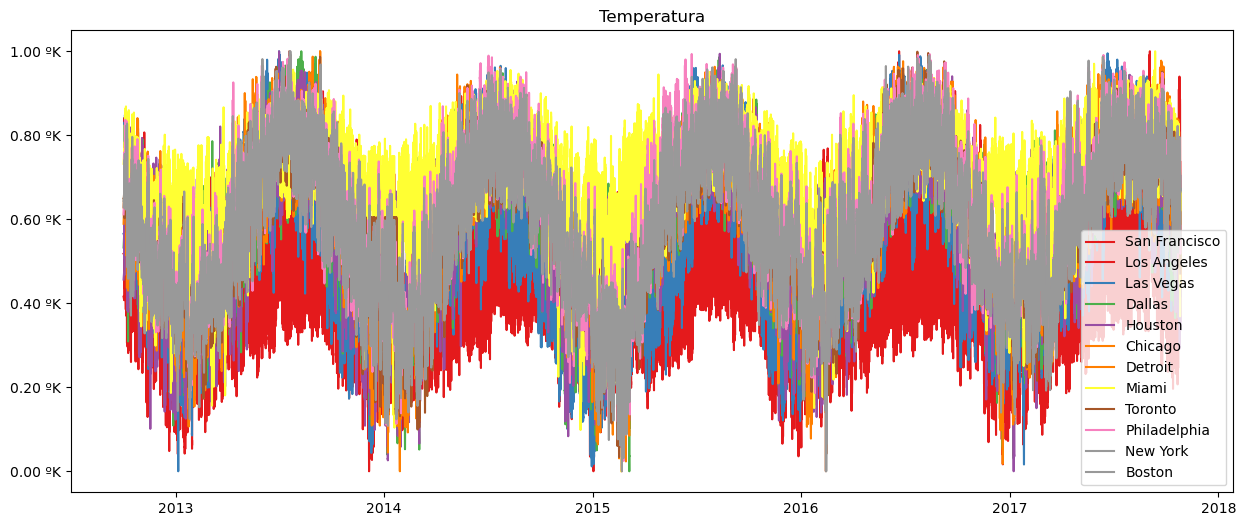

In [19]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15,6))
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%1.2f ºK'))

for i in range(len(headers)):
  # Generem una llista de dates a partir de la data inicial, afegint una hora per cada valor de la sèrie temporal
  x = [initial_moment + datetime.timedelta(hours=j, minutes=0) for j in range(matriu_norm[i].shape[0])]
  ax.plot(x, matriu_norm[i], label=headers[i], c=colors(i))
ax.legend()
ax.set_title("Temperatura")
plt.show()

Les xarxes neuronals aprenen patrons temporals amb les `finestres de predicció`. Cal transformar el dataset en una altra estructura utilitzant una quantitat d'observacions del passat per predir una altra quantitat d'observacions del futur. 

Es considera que per a predir una dada del futur es necessiten unes 15 del passat. Si volem predir les 24 hores següents necessitarem al menys 24x15 = 360 observacions del passat. 


In [21]:
import numpy as np

def create_sliding_windows(matrix, input_width=360, label_width=24):
    """
    Transforma una matriu de (num_ciutats, num_temps) en tensors de finestres lliscants.
    
    Paràmetres:
    - matrix: np.array de forma (12, 44424)
    - input_width: nombre de passos passats (historial) -> 360
    - label_width: nombre de passos futurs a predir -> 24
    """
    X_list = []
    y_list = []
    
    num_cities, num_timesteps = matrix.shape
    total_window_size = input_width + label_width
    
    # Recorrem ciutat per ciutat
    for i in range(num_cities):
        city_data = matrix[i]
        
        # Fem lliscar la finestra al llarg del temps d'aquesta ciutat
        for start_idx in range(num_timesteps - total_window_size + 1):
            end_input_idx = start_idx + input_width
            end_label_idx = end_input_idx + label_width
            
            # Extrec la finestra del passat (entrada)
            X_window = city_data[start_idx:end_input_idx]
            # Extrec la finestra del futur (objectiu / target)
            y_window = city_data[end_input_idx:end_label_idx]
            
            X_list.append(X_window)
            y_list.append(y_window)
            
    # Convertim les llistes a arrays de NumPy
    X = np.array(X_list)
    y = np.array(y_list)
    
    
    # Afegim la dimensió de features al final (passant de (N, 360) a (N, 360, 1)) util per a models LSTM/GRU que esperen una entrada 3D
    X = np.expand_dims(X, axis=-1)
    
    return X, y


X, y = create_sliding_windows(matriu_norm, input_width=360, label_width=24)

print("Forma de X (Entrada al model):", X.shape)  # Hauria de ser (~528492, 360, 1)
print("Forma de y (Objectiu a predir):", y.shape)  # Hauria de ser (~528492, 24)

Forma de X (Entrada al model): (528492, 360, 1)
Forma de y (Objectiu a predir): (528492, 24)


### Solució amb Xarxes neuronals Pytorch i LSTM

Creem la xarxa neuronal LSTM, observem que els seus paràmetres són que `input_size = 1`. Cal tenir en compte que és 1 perquè LSTM no rep els 360 valors d'una vegada, sino que van entrant un a un i va "memoritzant-los". Al final treu una eixida de 64 neurones com a resum del que ha resumir i interpretat la capa LSTM. Aquesta eixida va a una capa lineal `Full connected` amb una eixida de 24 prediccions a mode de regressió multioutput. 

In [ ]:
import torch
import torch.nn as nn

class LSTMTemperaturePredictor(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, output_size=24, num_layers=1):
        super(LSTMTemperaturePredictor, self).__init__()
        
        # Capa LSTM
        # batch_first=True fa que l'entrada sigui: (batch_size, seq_len, features)
        self.lstm = nn.LSTM(
            input_size=input_size, 
            hidden_size=hidden_size, 
            num_layers=num_layers, 
            batch_first=True
        )
        
        # Capa Densa (Lineal) per a l'eixida
        # Transforma l'estat ocult de l'LSTM (hidden_size) als 24 passos futurs
        self.fc = nn.Linear(hidden_size, output_size)
        
    def forward(self, x):
        # x forma d'entrada: (batch_size, 360, 1)
        
        # Passem les dades per l'LSTM
        # out: (batch_size, seq_len, hidden_size) -> conté la sortida de tots els passos
        # (hn, cn): estat ocult i de cèl·lula final
        out, (hn, cn) = self.lstm(x)
        
        # Ens interessa l'últim estat ocult de l'última capa de l'LSTM (hn[-1])
        # Això resumeix tota la informació de la finestra de 360 passos.
        # Forma de hn[-1]: (batch_size, hidden_size)
        last_hidden_state = hn[-1]
        
        # Passem l'estat per la capa densa
        # Forma final: (batch_size, 24)
        predictions = self.fc(last_hidden_state)
        
        return predictions

# --- INSTANCIAR EL MODEL ---
model = LSTMTemperaturePredictor(input_size=1, hidden_size=64, output_size=24)
print(model)

Ara cal transformar el dataset en tensors, configurar el Dataloader, dividir en train i test, definir la funció de pèrdua i el bucle d'entrenament. 